# 01 — Understanding Deep Learning


<h3 style="font-family: Times New Roman"><strong>II . Understanding Deep Learning</strong></h3>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">Having explored the historical background and inspiration behind deep learning, we can now delve into understanding the underlying mechanisms of this seemingly sci-fi technology. This journey will uncover how deep learning works, including the foundational concepts, methodologies, and real-world applications that make it a transformative force in modern technology.</p>

<h4 style="font-family: Times New Roman"><strong>Artificial Neural Network</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">Artificial Neural Networks (ANNs) consist of artificial neurons, known as <b>units</b>, organized into layers that form the entire network. These layers can range from having a few dozen units to millions, depending on the complexity required to learn hidden patterns in the data. Typically, an ANN includes an <b>input layer</b>, one or more <b>hidden layers</b>, and an <b>output layer</b>. The input layer receives external data for analysis, which is then processed through the hidden layers that transform the input into valuable information for the output layer. The output layer then generates a response based on the processed data.</p>

<center>
    <img src="figures/example1.png" width="50%">
</center>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">In most neural networks, units in different layers are interconnected, with each connection having a weight that determines the influence of one unit on another. As data flows through these connections, the neural network progressively learns from the data, ultimately producing an output from the output layer. </br > </br >Artificial neural networks are trained using a dataset. To teach an ANN to recognize a cat, it is presented with thousands of different cat images. The network learns to identify cats by analyzing these images. Once trained, the ANN is tested by classifying new images and determining whether they are cat images or not. The output is compared to a human-provided label. If the ANN misclassifies an image, backpropagation is used to refine the network's weights based on the error rate. This process iterates until the ANN can accurately recognize cat images with minimal errors.</p>

<h4 style="font-family: Times New Roman"><strong>Feedforward Neural Network</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">The feedforward neural network is one of the most basic artificial neural networks. In this ANN, the data or the input provided travels in a single direction. It enters into the ANN through the input layer and exits through the output layer while hidden layers may or may not exist. So the feedforward neural network has a front-propagated wave only and usually does not have backpropagation.</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    Assume that the neurons have a <b>sigmoid</b> activation function, perform a forward pass on the network. Assume that the actual output of $y$ is 1 and <b>learning rate</b> $\alpha$ is 0.9.
<br>
To calculate $H_1$, we need to calculate first the weighted sum of the input values added by the bias $\theta$.
<br>
$$Z = \sum_j{(w_{i,j} \cdot x_i)} + \theta_i$$
$Z_1 = (w_{11} \cdot x_1) + (w_{13} \cdot x_2) + (w_{15} \cdot x_3) + \theta_1$
<br>
$Z_2 = (w_{12} \cdot x_1) + (w_{14} \cdot x_2) + (w_{16} \cdot x_3) + \theta_2$
<br>
<br>
After computing the <b>weighted sum</b>, we introduce non-linearity to the output result by applying a nonlinear function. For this example, let's use <b>sigmoid function</b>.
<br>
$$\sigma = \frac{1}{1+e^{-Z_i}}$$
$H_1 = \sigma(Z_1)$
<br>
$H_2 = \sigma(Z_2)$
<br>
<br>
Now that we have computed the hidden layer's value, we can now proceed to computing the weighted sum for the output layer using the same procedure as how we compute the $Z_n$ and $H_n$.
<br>
<br>
$Z_3 = (w_{21} \cdot H_1) + (w_{22} \cdot H_2) + \theta_3$
<br>
$\hat{y} = \sigma(Z_3)$
<br>
<br>
This is how the calculations in a feedforward neural network are traversed from input to output.
</p>

<div class="alert alert-block alert-success" style="font-family: Times New Roman">
    <h4><strong>Laboratory Task 2</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    <b>Instruction:</b> Perform a single forward pass and compute for the error.
</p>

$$x = \begin{bmatrix} 1 \\ 0 \\ 1 \end{bmatrix}$$

$$y = \begin{bmatrix} 1 \end{bmatrix}$$

$$f=max(0, Z_n)$$

$$\text{hidden unit weights} = 
\begin{bmatrix}
w_{11} = 0.2 && w_{12} = -0.3 \\
w_{13} = 0.4 && w_{14} = 0.1 \\
w_{15} = -0.5 && w_{16} = 0.2
\end{bmatrix}$$

$$\text{output unit weights} = 
\begin{bmatrix}
w_{21} = -0.3 \\
w_{22} = -0.2
\end{bmatrix}$$

$$\theta = 
\begin{bmatrix}
\theta_{1} = -0.4 \\
\theta_{2} = 0.2 \\
\theta_{3} = 0.1
\end{bmatrix}$$
</div>

### Student solution — Lab Task 2

This is the completed work for the task above. A separate, runnable notebook is also available in the **Completed Lab Activities** navigation section.


In [1]:
import numpy as np

x = np.array([1.0, 0.0, 1.0])
y = 1.0
W_h = np.array([[0.2, -0.3], [0.4, 0.1], [-0.5, 0.2]])
b_h = np.array([-0.4, 0.2])
W_o = np.array([-0.3, -0.2])
b_o = 0.1

def relu(z):
    return np.maximum(0, z)

z_h = x @ W_h + b_h
h = relu(z_h)
z_o = float(h @ W_o + b_o)
y_hat = float(relu(z_o))
error = y - y_hat
squared_error = error ** 2
half_squared_error = 0.5 * squared_error

print('Hidden weighted sums:', z_h)
print('Hidden activations:', h)
print(f'Output weighted sum: {z_o:.4f}')
print(f'Predicted output: {y_hat:.4f}')
print(f'Error (actual - predicted): {error:.4f}')
print(f'Squared error / one-sample MSE: {squared_error:.4f}')
print(f'Half-squared error: {half_squared_error:.4f}')

assert np.allclose(z_h, [-0.7, 0.1])
assert np.isclose(y_hat, 0.08)
assert np.isclose(squared_error, 0.8464)


Hidden weighted sums: [-0.7  0.1]
Hidden activations: [0.  0.1]
Output weighted sum: 0.0800
Predicted output: 0.0800
Error (actual - predicted): 0.9200
Squared error / one-sample MSE: 0.8464
Half-squared error: 0.4232


**Interpretation:** The first hidden neuron is inactive because its weighted sum is negative. The model predicts **0.08** instead of the target **1.00**, so the initial prediction has a relatively large error. The next activity uses backpropagation to update the parameters.


<h4 style="font-family: Times New Roman"><strong>Backward Propagation of Errors</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">Backward propagation a.k.a backprop or backward pass is a fundamental algorithm used for training artificial neural networks. It involves a two-step process: a forward pass and a backward pass. During the forward pass, input data is fed through the network, and the output is generated. The error, or the difference between the predicted output and the actual target, is then calculated. In the backward pass, this error is propagated back through the network, layer by layer, to update the weights and biases. This is done by computing the gradient of the loss function with respect to each weight using the chain rule of calculus. By iteratively adjusting the weights in the direction that reduces the error, backpropagation helps the network learn and improve its performance over time. This process continues until the network's predictions are sufficiently accurate or another stopping criterion is met.</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
The initial value for $\hat{y}$ is not the optimal value since the parameters used were just randomly selected. Therefore, after the forward propagation, a backward propagation algorithm is employed to update the parameters ($w$ and $\theta$).
<br>
The error at the output layer is calculated as the difference between the predicted output ($\hat{y}$) and the actual output ($y$):
<br>
$$\delta = \hat{y} - y$$
<br>
Compute Hidden Layer Error ($\delta_h$)
<br>
$$\delta_h = (\delta_o W^T_o) \cdot \sigma'(Z_h)$$
<br>
Where:
<br>
<ul style="font-family:Times New Roman">
    <li> $\sigma'(Z_h)$ is the derivative of the sigmoid activation function applied to the hidden layer activations $Z_h$:</li>
    <li> $\sigma'(Z_h) = A_h \cdot (1 - A_h)$</li>
    <li> $W^T_o$ is the transpose of the output weights matrix $W_o$.</li>
</ul>
</p>
<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
Calculate Gradients
<br>
Once we have the errors ($\delta_o$ and $\delta_h$), we compute the gradients of the error with respect to the weights ($W_o$ and $W_h$).
<br>
Gradients for Output Layer Weights ($\frac{\partial E}{\partial W_o}$)
<br>
$$\frac{\partial E}{\partial W_o} = A\frac{T}{h} \delta_o$$
<br>
Gradients for Hidden Layer Weights ($\frac{\partial E }{\partial W_h}$)
<br>
$$\frac{\partial E}{\partial W_h} = X^T \delta_h$$
<br>
Finally, the weights are updated using the gradients and the learning rate ($\alpha$).
</p>

<div class="alert alert-block alert-success" style="font-family: Times New Roman">
    <h4><strong>Laboratory Task 3</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    <b>Instruction:</b> Perform a forward and backward propagation in python using the inputs from <b>Laboratory Task 2</b>
</p>

```python
x = np.array([1, 0, 1])
y = np.array([1])

# use relu as the activation function.

# learning rate
lr = 0.001
```
</div>

### Student solution — Lab Task 3

This is the completed work for the task above. A separate, runnable notebook is also available in the **Completed Lab Activities** navigation section.


In [1]:
import numpy as np

x = np.array([1., 0., 1.])
y = np.array([1.])
lr = 0.001
W_h = np.array([[0.2, -0.3], [0.4, 0.1], [-0.5, 0.2]], dtype=float)
b_h = np.array([-0.4, 0.2], dtype=float)
W_o = np.array([[-0.3], [-0.2]], dtype=float)
b_o = np.array([0.1], dtype=float)

relu = lambda z: np.maximum(0, z)
relu_derivative = lambda z: (z > 0).astype(float)

# Forward pass
z_h = x @ W_h + b_h
h = relu(z_h)
z_o = h @ W_o + b_o
y_pred_before = relu(z_o)
loss_before = float(0.5 * np.sum((y_pred_before - y)**2))

# Backpropagation for L = 0.5 * (prediction - target)^2
delta_o = (y_pred_before - y) * relu_derivative(z_o)
grad_W_o = np.outer(h, delta_o)
grad_b_o = delta_o.copy()
delta_h = (W_o @ delta_o) * relu_derivative(z_h)
grad_W_h = np.outer(x, delta_h)
grad_b_h = delta_h.copy()

# Gradient descent update
W_o = W_o - lr * grad_W_o
b_o = b_o - lr * grad_b_o
W_h = W_h - lr * grad_W_h
b_h = b_h - lr * grad_b_h

# Check the change using a NEW forward pass
z_h_new = x @ W_h + b_h
h_new = relu(z_h_new)
y_pred_after = relu(h_new @ W_o + b_o)
loss_after = float(0.5 * np.sum((y_pred_after - y)**2))

print('Before: prediction =', y_pred_before, 'loss =', round(loss_before, 8))
print('Output delta:', delta_o)
print('Hidden delta:', delta_h)
print('Updated input-to-hidden weights:\n', W_h)
print('Updated hidden-to-output weights:\n', W_o)
print('Updated hidden biases:', b_h)
print('Updated output bias:', b_o)
print('After: prediction =', y_pred_after, 'loss =', round(loss_after, 8))

assert np.isclose(y_pred_before.item(), 0.08)
assert np.isclose(loss_before, 0.4232)
assert loss_after < loss_before, 'The first gradient step should reduce the loss.'


Before: prediction = [0.08] loss = 0.4232
Output delta: [-0.92]
Hidden delta: [0.    0.184]
Updated input-to-hidden weights:
 [[ 0.2      -0.300184]
 [ 0.4       0.1     ]
 [-0.5       0.199816]]
Updated hidden-to-output weights:
 [[-0.3     ]
 [-0.199908]]
Updated hidden biases: [-0.4       0.199816]
Updated output bias: [0.10092]
After: prediction = [0.08103955] loss = 0.42224416


**Interpretation:** The first ReLU hidden neuron receives no gradient because its pre-activation is \(-0.7\). The second neuron and the output unit do receive gradients. After one SGD step the loss decreases slightly, demonstrating how backpropagation adjusts weights and biases toward the target. This activity intentionally performs **one update**, not an entire training run.


<h4 style="font-family: Times New Roman"><strong>Introduction to PyTorch</strong></h4>

<center><img src="https://upload.wikimedia.org/wikipedia/commons/9/96/Pytorch_logo.png?20211003060202" width="15%"></center>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">PyTorch is a powerful and widely-used open-source framework for deep learning, developed by Facebook's AI Research lab. It is designed to provide flexibility and speed for both research and production environments. PyTorch's primary strength lies in its dynamic computation graph, which allows for real-time changes and debugging, making it easier to experiment with new ideas. This is in contrast to static computation graphs used by other frameworks like TensorFlow. PyTorch supports a range of applications, from natural language processing to computer vision, through its extensive library of pre-built modules and tools. Additionally, its integration with Python makes it accessible to a large community of developers and researchers, fostering rapid development and collaboration. With a strong emphasis on simplicity and performance, PyTorch has become a go-to tool for many in the deep learning community.</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>Setting up the Virtual Enviroment</strong></p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">A virtual environment is a self-contained directory that isolates a specific Python environment, allowing users to manage dependencies and packages for different projects independently. This ensures that each project can have its own unique set of libraries and versions without conflicts, avoiding issues that arise from global installations. Virtual environments are particularly useful for maintaining consistent development environments, making it easier to manage project-specific dependencies and ensuring that applications run smoothly across different setups. Tools like <b>venv</b> and <b>virtualenv</b> facilitate the creation and management of these environments. We can create a virtual environment using either <b>pip</b> or <b>conda</b>.</p>

<ol style="font-family:Times New Roman; font-size:15px">
    <strong><li>With PIP</li></strong>
    <ul>
        <li>Make sure that you have installed python and have its directory path added in the machine's environment variables.</li>
        <li>Create a new folder, make sure that you know the directory of the new folder that you have created.</li>
        <li>Open command prompt and change the directory to the new folder that you created.</li>
        <li>Considering that you already have configured pip in the environment variables, you can now install libraries.</li>
        <li>Run command <div class="custom-inline-code" class="cd">pip install virtualenv</div>.</li>
        <li>You can create a virtual enviroment with a specific python version but only if the specific version is installed in your system.</li>
        <li>Run command <div class="custom-inline-code">virtualenv -p /path/to/pythonX.X /path/to/new/virtual/environment</div></li>
        <li>Replace <div class="custom-inline-code">/path/to/pythonX.X</div> with the path to the desired Python executable (e.g., <div class="custom-inline-code">/usr/bin/python3.8</div>) and <div class="custom-inline-code">/path/to/new/virtual/environment</div> with the path where you want to create the virtual environment.</li>
        <li>Activate the virtual environment, make sure that you are inside the directory where the environment's folder is also under.</li>
        <li>Run command <div class="custom-inline-code">env_name/Scripts/activate</div>.</li>
        <li>Replace <div class="custom-inline-code">env_name</div> with the name of the environment you created.</li>
    </ul>
    <br>
    <strong><li>With CONDA</li></strong>
    <ul>
        <li>Make sure that <a href="https://www.anaconda.com/">anaconda</a> is installed in you system.</li>
        <li>Open anaconda prompt and run command <div class="custom-inline-code">conda create -n <myenv> python=3.X</div></li>
        <li>Activate the environment by running the command <div class="custom-inline-code">conda activate env_name</div>.</li>
        <li>Replace <div class="custom-inline-code">env_name</div> with the name of the environment you created.</li>
    </ul>
</ol>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>PyTorch Installation</strong></p>

<ol style="font-family: Times New Roman; font-size:15px">
    <li>Make sure that python is installed in your local device, the stable version of pytorch runs on python version 3.6 to 3.9. Make sure that your python version is in between this range. You can check the python version using command the command;</li>
    <br>
    <div class="custom-alert">
        <div class="custom-code">python --version</div>
    </div>
    <br>
    <li>Activate the virtual environment, for this demonstration, let's just use the conda virtual enviroment.</li>
    <br>
    <div class="custom-alert">
        <div class="custom-code">conda activate env_name</div>
    </div>
    <br>
    <li>Go to <a href="https://pytorch.org/get-started/locally/">https://pytorch.org/get-started/locally/</a> and select appropriate machine configurations and copy the generated command. <br> If you have a CUDA enabled GPU, you can download and install CUDA toolkit version 11.8 or 12.1 first. Otherwise you may only select CPU.</li>
    <br>
    <center><img src="figures/torch.png" width="600px"></center>
    <br>
    <li>Paste the command in the anaconda prompt where you activated the virtual enviroment and wait patiently. <br> Just click <div class="custom-inline-code">Y</div> when prompted with a question to proceed installation.</li>
    <br>
    <center><img src="figures/torch2.png" width="600px"></center>
</ol>

<h4 style="font-family: Times New Roman"><strong>PyTorch Components</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">Let's have linear regression as a case study to study the different components of PyTorch.  These are the following components we will be covering:</p>

<ol style="font-family: Times New Roman; font-size:15px">
    <li>Specifying input and target</li>
    <li>Dataset and DataLoader</li>
    <li><div class="custom-inline-code">nn.Linear</div> (Dense) </li>
    <li>Define loss function</li>
    <li>Define optimizer function</li>
    <li>Train the model</li>
</ol>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    Consider this data:
    <br>
    <img src="figures/japan.png" class="center" width="60%">
    <br>
    In a linear regression model, each target variable is estimated to be a weighted sum of the input variables, offset by some constant, known as a bias :
    <br>
    <br>
$$\text{yield}_\text{apple}  = w_{11} \cdot \text{temp} + w_{12} \cdot \text{rainfall} + w_{13} \cdot \text{humidity} + b_{1}$$
$$\text{yield}_\text{orange} = w_{21} \cdot \text{temp} + w_{22} \cdot \text{rainfall} + w_{23} \cdot \text{humidity} + b_{2}$$
    <br>
    Visually, it means that the yield of apples is a linear or planar function of temperature, rainfall and humidity:
    <br>
    <img src="figures/japan2.png" class="center" width="60%">
    <br>
    The learning part of linear regression is to figure out a set of weights <strong>w11, w12,... w23, b1 & b2</strong> using gradient descent.
    <br>
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>Sample Implementation</strong></p>

In [1]:
import torch
import numpy as np
import sys

In [2]:
torch.__version__

'2.7.0+cu128'

In [3]:
#We can check whether we have gpu
device = torch.device("cuda:0" if (torch.cuda.is_available()) else "cpu")
print("Device: ", device)

Device:  cuda:0


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>1. Specifiying input and target</strong></p>

In [4]:
# Input (temp, rainfall, humidity)
x_train = np.array([
    [73, 67, 43], [91, 88, 64], [87, 134, 58], 
    [102, 43, 37], [69, 96, 70], [73, 67, 43], 
    [91, 88, 64], [87, 134, 58], [102, 43, 37], 
    [69, 96, 70], [73, 67, 43], [91, 88, 64], 
    [87, 134, 58], [102, 43, 37], [69, 96, 70]], 
                   dtype='float32')

# Targets (apples, oranges)
y_train = np.array([
    [56, 70], [81, 101], [119, 133], 
    [22, 37], [103, 119], [56, 70], 
    [81, 101], [119, 133], [22, 37], 
    [103, 119], [56, 70], [81, 101], 
    [119, 133], [22, 37], [103, 119]], 
                   dtype='float32')

In [5]:
inputs = torch.from_numpy(x_train)
targets = torch.from_numpy(y_train)
print(inputs.size())
print(targets.size())

torch.Size([15, 3])
torch.Size([15, 2])


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>2. Dataset and DataLoader</strong></p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    PyTorch provides two data primitives: <a href="https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader"><strong><tt>torch.utils.data.DataLoader</tt></strong></a> and <a href="https://pytorch.org/vision/0.18/datasets.html"><strong><tt>torch.utils.data.Dataset</tt></strong></a> that allow you to use pre-loaded datasets as well as your own data. Dataset stores the samples and their corresponding labels, and DataLoader wraps an iterable around the Dataset to enable easy access to the samples.
</p>

In [6]:
from torch.utils.data import TensorDataset

In [9]:
# Define dataset
train_ds = TensorDataset(inputs, targets)
train_ds[0:6]

(tensor([[ 73.,  67.,  43.],
         [ 91.,  88.,  64.],
         [ 87., 134.,  58.],
         [102.,  43.,  37.],
         [ 69.,  96.,  70.],
         [ 73.,  67.,  43.]]),
 tensor([[ 56.,  70.],
         [ 81., 101.],
         [119., 133.],
         [ 22.,  37.],
         [103., 119.],
         [ 56.,  70.]]))

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    We'll now create a <strong><tt>DataLoader</tt></strong>, which can split the data into batches of a predefined size while training. It also provides other utilities like shuffling and random sampling of the data.
</p>

In [10]:
from torch.utils.data import DataLoader

In [11]:
# Define data loader
batch_size = 3
train_dl = DataLoader(train_ds, batch_size, shuffle=True)

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
The <strong><tt>DataLoader</tt></strong> is typically used in a for-in loop. Let's look at an example
</p>

In [12]:
for xb, yb in train_dl:
    print(xb)
    print(yb)
    break

tensor([[ 91.,  88.,  64.],
        [ 87., 134.,  58.],
        [ 87., 134.,  58.]])
tensor([[ 81., 101.],
        [119., 133.],
        [119., 133.]])


<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    In each iteration, the data loader returns one batch of data, with the given batch size. If shuffle is set to True, it shuffles the training data before creating batches. Shuffling helps randomize the input to the optimization algorithm, which can lead to faster reduction in the loss.
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>3. Define some Layer - <strong><tt>nn.Linear</tt></strong></strong></p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
Instead of initializing the weights & biases manually, we can define the model using the <strong><tt>nn.Linear</tt></strong> class from PyTorch, which does it automatically.
</p>

In [13]:
import torch.nn as nn

In [15]:
# Define model
model = nn.Linear(3, 2)  #nn.Linear assume this shape (in_features, out_features)
print(model.weight)
print(model.weight.size()) # (out_features, in_features)
print(model.bias)
print(model.bias.size()) #(out_features)

Parameter containing:
tensor([[-0.5229,  0.3903, -0.0960],
        [ 0.3899,  0.2845, -0.1523]], requires_grad=True)
torch.Size([2, 3])
Parameter containing:
tensor([ 0.4995, -0.3051], requires_grad=True)
torch.Size([2])


<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
In fact, our model is simply a function that performs a matrix multiplication of the <strong><tt>inputs</tt></strong> and the weights <strong><tt>w</tt></strong> and adds the bias <strong><tt>b</tt></strong> (for each observation)
<br>
<img src = "figures/dot.png" class="center" width="60%">
<br>
PyTorch models also have a helpful <strong><tt>.parameters</tt></strong> method, which returns a list containing all the weights and bias matrices present in the model. For our linear regression model, we have one weight matrix and one bias matrix.
</p>

In [16]:
# Parameters
list(model.parameters())  #model.param returns a generator

[Parameter containing:
 tensor([[-0.5229,  0.3903, -0.0960],
         [ 0.3899,  0.2845, -0.1523]], requires_grad=True),
 Parameter containing:
 tensor([ 0.4995, -0.3051], requires_grad=True)]

In [17]:
#we can print the complexity by the number of parameters
print(sum(p.numel() for p in model.parameters() if p.requires_grad))

8


<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
We can use the <strong><tt>model(tensor)<tt></strong> API to perform a forward-pass that generate predictions.
</p>

In [18]:
# Generate predictions
preds = model(inputs)
preds

tensor([[-15.6512,  40.6688],
        [-18.8838,  50.4627],
        [  1.7370,  62.9027],
        [-39.6054,  46.0624],
        [ -4.8343,  43.2468],
        [-15.6512,  40.6688],
        [-18.8838,  50.4627],
        [  1.7370,  62.9027],
        [-39.6054,  46.0624],
        [ -4.8343,  43.2468],
        [-15.6512,  40.6688],
        [-18.8838,  50.4627],
        [  1.7370,  62.9027],
        [-39.6054,  46.0624],
        [ -4.8343,  43.2468]], grad_fn=<AddmmBackward0>)

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>4. Define Loss Function</strong></p>

The <strong><tt>nn<tt></strong> module contains a lot of useful loss function like this:

In [21]:
criterion_mse = nn.MSELoss()
criterion_softmax_cross_entropy_loss = nn.CrossEntropyLoss()

In [22]:
mse = criterion_mse(preds, targets)
print(mse)
print(mse.item())  ##print out the loss number

tensor(5843.3374, grad_fn=<MseLossBackward0>)
5843.33740234375


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>5. Define the Optimizer</strong></p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
We use  <strong><tt>optim.SGD</tt></strong> to perform stochastic gradient descent where samples are selected in batches (often with random shuffling) instead of as a single group.  Note that  <strong><tt>model.parameters()</tt></strong> is passed as an argument to <strong><tt>optim.SGD</tt></strong>.
</p>

In [23]:
# Define optimizer
#momentum update the weight based on past gradients also, which will be useful for getting out of local max/min
#If our momentum parameter was $0.9$, we would get our current grad + the multiplication of the gradient 
#from one time step ago by $0.9$, the one from two time steps ago by $0.9^2 = 0.81$, etc.

opt = torch.optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><strong>6. Training - Putting Everything Together</strong></p>

In [24]:
# Utility function to train the model
def fit(num_epochs, model, loss_fn, opt, train_dl):
    
    # Repeat for given number of epochs
    for epoch in range(num_epochs):
        
        # Train with batches of data
        for xb,yb in train_dl:
            
            xb.to(device) #move them to gpu if possible, if not, it will be cpu
            yb.to(device)
                    
            # 1. Predict
            pred = model(xb)
                      
            # 2. Calculate loss
            loss = loss_fn(pred, yb)
            
            # 3. Calculate gradient
            opt.zero_grad()  #if not, the gradients will accumulate
            loss.backward()
            
            # Print out the gradients.
            print ('dL/dw: ', model.weight.grad) 
            print ('dL/db: ', model.bias.grad)
            
            # 4. Update parameters using gradients
            opt.step()
            
        # Print the progress
        if (epoch+1) % 10 == 0:
            sys.stdout.write("\rEpoch [{}/{}], Loss: {:.4f}".format(epoch+1, num_epochs, loss.item()))

In [25]:
#train for 100 epochs
fit(100, model, criterion_mse, opt, train_dl)

dL/dw:  tensor([[-7253.5107, -7980.8330, -5673.9893],
        [-3989.0144, -4561.5933, -3266.1177]])
dL/db:  tensor([-93.1231, -51.8739])
dL/dw:  tensor([[6317.6807, 9530.1025, 4680.2524],
        [3015.4019, 4581.2827, 2157.7104]])
dL/db:  tensor([76.6555, 35.9308])
dL/dw:  tensor([[5101.2090, 3052.9473, 2456.9558],
        [6531.1250, 3273.0288, 2718.4253]])
dL/db:  tensor([54.3753, 66.5435])
dL/dw:  tensor([[-3471.2095, -3010.7944, -2225.2834],
        [-2754.6519, -2727.7654, -1977.2488]])
dL/db:  tensor([-37.3935, -30.4098])
dL/dw:  tensor([[-5094.1104, -6364.0952, -3211.2446],
        [-5283.4497, -6582.5503, -3328.3455]])
dL/db:  tensor([-63.8017, -66.2372])
dL/dw:  tensor([[2310.9473, 2650.9524, 1427.3353],
        [2101.8816, 2474.5928, 1306.1230]])
dL/db:  tensor([29.7799, 26.8611])
dL/dw:  tensor([[6407.0415, 3428.4421, 2655.8489],
        [5948.3213, 3189.9905, 2468.8975]])
dL/db:  tensor([68.5234, 63.6724])
dL/dw:  tensor([[ 579.1582,  407.0865,  300.1279],
        [1177.3

In [26]:
# Generate predictions
preds = model(inputs)
loss = criterion_mse(preds, targets)
print(loss.item())

114.18843078613281


In [27]:
y_train = np.array([
    [56, 70], [81, 101], [119, 133], 
    [22, 37], [103, 119], [56, 70], 
    [81, 101], [119, 133], [22, 37], 
    [103, 119], [56, 70], [81, 101], 
    [119, 133], [22, 37], [103, 119]], 
                  )

In [28]:
y_train

array([[ 56,  70],
       [ 81, 101],
       [119, 133],
       [ 22,  37],
       [103, 119],
       [ 56,  70],
       [ 81, 101],
       [119, 133],
       [ 22,  37],
       [103, 119],
       [ 56,  70],
       [ 81, 101],
       [119, 133],
       [ 22,  37],
       [103, 119]])

In [29]:
preds

tensor([[ 67.2225,  78.6182],
        [ 93.0148, 109.8101],
        [131.5451, 141.5371],
        [ 36.9403,  52.0892],
        [107.6788, 123.0793],
        [ 67.2225,  78.6182],
        [ 93.0148, 109.8101],
        [131.5451, 141.5371],
        [ 36.9403,  52.0892],
        [107.6788, 123.0793],
        [ 67.2225,  78.6182],
        [ 93.0148, 109.8101],
        [131.5451, 141.5371],
        [ 36.9403,  52.0892],
        [107.6788, 123.0793]], grad_fn=<AddmmBackward0>)

In [30]:
targets

tensor([[ 56.,  70.],
        [ 81., 101.],
        [119., 133.],
        [ 22.,  37.],
        [103., 119.],
        [ 56.,  70.],
        [ 81., 101.],
        [119., 133.],
        [ 22.,  37.],
        [103., 119.],
        [ 56.,  70.],
        [ 81., 101.],
        [119., 133.],
        [ 22.,  37.],
        [103., 119.]])

<div class="alert alert-block alert-success" style="font-family: Times New Roman">
    <h4><strong>Laboratory Task 4</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    <b>Instruction:</b> Train a linear regression model in PyTorch using a regression dataset. Use the following parameters.
</p>

<ul>
    <li>Criterion: MSE Loss</li>
    <li>Fully Connected Layers x 2</li>
    <li>Batch Size: 8</li>
    <li>Optimizer: SGD</li>
    <li>Epoch: 1000</li>
</ul>
</div>

### Student solution — Lab Task 4

This is the completed work for the task above. A separate, runnable notebook is also available in the **Completed Lab Activities** navigation section.


In [1]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(1)  # modest CPU use; training also works without this line

# Built-in regression dataset (442 samples, 10 features)
data = load_diabetes()
X = data.data.astype(np.float32)
y = data.target.astype(np.float32).reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

# Fit scaling on training data only
x_scaler = StandardScaler()
y_scaler = StandardScaler()
X_train_s = x_scaler.fit_transform(X_train).astype(np.float32)
X_test_s = x_scaler.transform(X_test).astype(np.float32)
y_train_s = y_scaler.fit_transform(y_train).astype(np.float32)

train_data = TensorDataset(torch.from_numpy(X_train_s), torch.from_numpy(y_train_s))
train_loader = DataLoader(train_data, batch_size=8, shuffle=True)

# Exactly TWO fully connected (nn.Linear) layers
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 12),
    nn.ReLU(),
    nn.Linear(12, 1)
)
criterion = nn.MSELoss()             # required MSE loss
optimizer = torch.optim.SGD(model.parameters(), lr=0.004, weight_decay=0.05)  # required SGD
EPOCHS = 1000                      # required training epochs
BATCH_SIZE = 8                     # required batch size
assert train_loader.batch_size == BATCH_SIZE
assert len([module for module in model.modules() if isinstance(module, nn.Linear)]) == 2

print('Training samples:', len(train_data))
print('Test samples:', len(X_test))
print('Model:', model)


Training samples: 353
Test samples: 89
Model: Sequential(
  (0): Linear(in_features=10, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=1, bias=True)
)


In [2]:
# Train for 1000 epochs with batches of 8
history = []
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        predictions = model(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    epoch_mse = total_loss / len(train_data)
    history.append(epoch_mse)
    if epoch == 0 or (epoch + 1) % 200 == 0:
        print(f'Epoch {epoch+1:4d}/{EPOCHS}: training MSE (scaled target) = {epoch_mse:.5f}')

# Evaluate on held-out testing data, restoring original units
model.eval()
with torch.no_grad():
    pred_test_scaled = model(torch.from_numpy(X_test_s)).numpy()
y_pred = y_scaler.inverse_transform(pred_test_scaled).reshape(-1)
y_true = y_test.reshape(-1)

mse_test = mean_squared_error(y_true, y_pred)
rmse_test = float(np.sqrt(mse_test))
mae_test = mean_absolute_error(y_true, y_pred)
r2_test = r2_score(y_true, y_pred)

print(f'\nTest MSE: {mse_test:.3f}')
print(f'Test RMSE: {rmse_test:.3f}')
print(f'Test MAE: {mae_test:.3f}')
print(f'Test R²: {r2_test:.3f}')

assert len(history) == 1000
assert np.isfinite(mse_test) and np.isfinite(rmse_test)


Epoch    1/1000: training MSE (scaled target) = 1.12355


Epoch  200/1000: training MSE (scaled target) = 0.44412


Epoch  400/1000: training MSE (scaled target) = 0.43883


Epoch  600/1000: training MSE (scaled target) = 0.43543


Epoch  800/1000: training MSE (scaled target) = 0.43332


Epoch 1000/1000: training MSE (scaled target) = 0.43230

Test MSE: 2609.875
Test RMSE: 51.087
Test MAE: 40.425
Test R²: 0.507


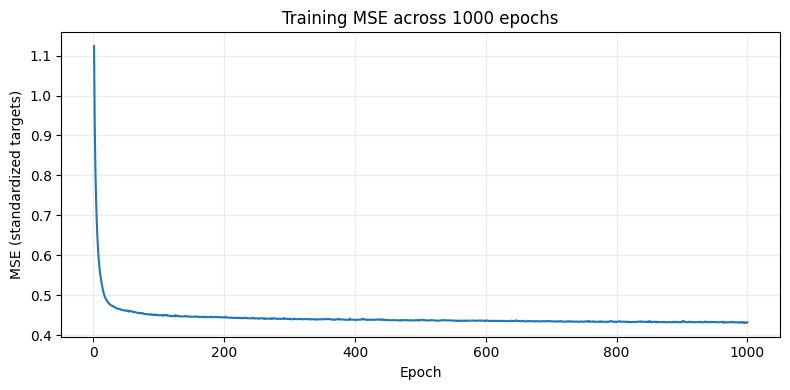

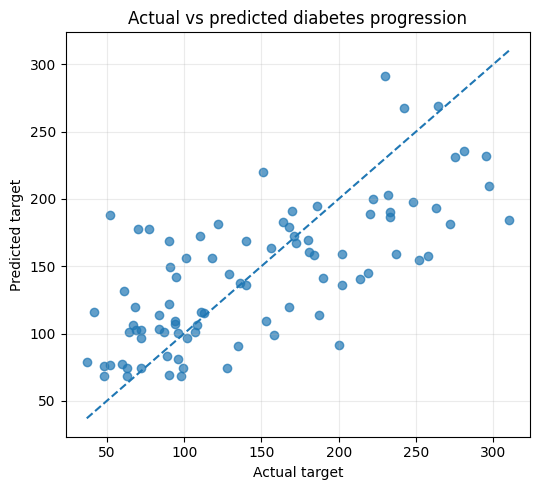

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(history)+1), history)
ax.set(title='Training MSE across 1000 epochs', xlabel='Epoch', ylabel='MSE (standardized targets)')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_true, y_pred, alpha=0.7)
lim_low = min(y_true.min(), y_pred.min())
lim_high = max(y_true.max(), y_pred.max())
ax.plot([lim_low, lim_high], [lim_low, lim_high], '--')
ax.set(title='Actual vs predicted diabetes progression', xlabel='Actual target', ylabel='Predicted target')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Interpretation:** The training curve shows how the model’s MSE changes over 1000 epochs. Test MSE and RMSE summarize prediction error on unseen samples, while R² describes how well the regression predicts variation in the diabetes progression target. The two linear layers are separated by ReLU; the last layer has no activation because regression predictions are continuous. The evaluation metrics come from the code output and should not be claimed before running it.
